
# ILLM Lab 3 — BPE & WordPiece Subword Tokenization on IndicCorpV2

Builds a train/dev/test split for **one language** from IndicCorpV2, then implements
**BPE** and **WordPiece** entirely from scratch (no `tokenizers`, `sentencepiece`, or
`sklearn`), and studies how tokenization behavior changes with **training‑data size**
and **vocabulary size**.

---

## 1. Deep analysis of the assignment

| # | Requirement | What it means concretely |
|---|---|---|
| 1 | Train/dev/test split; dev & test = 1000 sentences each, rest = train; **dev/test must NOT be sentences of similar length** — "maintain a length distribution" | Dev and test must be constructed by **stratified sampling over sentence length**, not plain random sampling — otherwise a random 1000‑sample could (by chance, or if long sentences are rarer) skew toward the corpus's modal length. We bucket the full sentence pool into length deciles and sample proportionally from every bucket into both dev and test, so each set spans the *full* range of lengths actually present in the corpus. |
| 2 | Implement BPE and WordPiece; tokenize dev/test | Both are subword tokenizers learned by iteratively merging symbol pairs, but with **different merge‑selection criteria** (BPE: most frequent pair; WordPiece: highest pointwise‑mutual‑information‑style score) and **different pieces**: BPE uses a `</w>` end‑of‑word marker, WordPiece uses a `##` continuation‑prefix convention (and a different, greedy‑longest‑match encoding algorithm at inference time). |
| 3 | Test 4 training sizes: 100k / 300k / 500k / 1,000,000 sentences; show how tokenization changes | A **single‑factor sweep**: fix vocabulary size, vary training‑corpus size, retrain, and re‑tokenize the *same, fixed* dev/test sets each time, tracking metrics like tokens‑per‑word. |
| 4 | Test 3 vocabulary sizes: 20,000 / 30,000 / 50,000; show the impact | A second **single‑factor sweep**: fix training size, vary target vocabulary size. |

**Design decision (stated explicitly, since the assignment doesn't specify this):** we
treat Parts 3 and 4 as two **independent single‑factor ablations**, not a full
4×3 grid — i.e. Part 3 fixes vocab size at a sensible default (30,000, the middle of
Part 4's options) while sweeping training size across all 4 values; Part 4 fixes
training size at a sensible default (500,000) while sweeping vocab size across all 3
values. This is both the more natural reading of "test on 4 sizes... **similarly** test
on 3 vocab sizes" (two separate studies) and far more computationally tractable than a
full 12‑combination × 2‑algorithm grid — several of those combinations (1,000,000
sentences × 50,000‑merge vocabulary) would be extremely expensive to run twice. The
one configuration shared by both sweeps (500,000 sentences, 30,000 vocabulary) is
trained **once** and reused in both tables, so nothing is wastefully duplicated.

## 2. How BPE and WordPiece actually differ (and why both need custom code)

Both start from the same idea: represent every training word as a sequence of
characters, then repeatedly **merge the best adjacent symbol pair** into a new symbol,
recording each merge, until the vocabulary reaches a target size. They differ in two
places:

**(a) Which pair counts as "best" at each step**
```
BPE:        best pair = argmax_pair  count(pair)
WordPiece:  best pair = argmax_pair  count(pair) / ( count(left_symbol) * count(right_symbol) )
```
WordPiece's score is a mutual‑information‑style statistic: it prefers pairs that
co‑occur *more than their individual frequencies would predict*, which tends to avoid
prematurely merging extremely common but low‑information character pairs, and instead
favors pairs that are more uniquely, reliably adjacent.

**(b) How a NEW word gets tokenized once training is done**
```
BPE:        apply the learned merge rules to the word's characters, IN THE ORDER
            they were learned, repeatedly, until no more rules apply.
WordPiece:  greedily match the LONGEST substring (with a "##" prefix for anything
            after the first piece) that exists in the final learned vocabulary,
            starting from the left, falling back to a single [UNK] token for the
            whole word if even one character was never seen in training.
```

**A genuinely tricky implementation detail we ran into (worth documenting):**
WordPiece's score denominator depends on each symbol's *global* frequency across the
**entire** training corpus, not just the words containing the candidate pair. A
symbol's global count only ever decreases as training proceeds (merges consume
occurrences, they never create new ones for a symbol that already existed), so a
pair's true score can only ever *increase* relative to any earlier snapshot. A naive
"lazy" priority queue — which assumes stale cached values only ever *overestimate* the
true value, a totally standard assumption for BPE's plain frequency counts — silently
breaks for WordPiece, because it *understates* pairs whose shared symbol later became
rarer elsewhere in the corpus, burying genuinely-best merges arbitrarily deep in the
queue. We catch this in Section 6 with a hand‑checkable toy corpus and a from‑scratch
"slow but obviously correct" reference trainer, and fix it in Section 7's fast trainer
by explicitly re‑scoring every pair touching a just‑merged symbol's two halves,
immediately after each merge — not only the pairs local to the specific words that
merge touched.

## 3. Plan for this notebook

```
Pick ONE language (default: Hindi / hin_Deva -- largest IndicCorpV2 resource,
        needed to reach 1,000,000 sentences; change LANGUAGE_CODE to switch)
        ▼
Stream + sentence-tokenize up to ~1,002,000 sentences (checkpointed to disk)
        ▼
Length-stratified sampling: pull 1000 dev + 1000 test sentences spanning the
        FULL length distribution; remaining sentences become the train pool
        ▼
Nested training subsets: shuffle the train pool ONCE, take prefixes of size
        100k / 300k / 500k / 1,000,000 (so every larger subset is a strict
        superset of every smaller one -- isolates the effect of size alone)
        ▼
BPE trainer (fast, heap-based) + WordPiece trainer (fast, lazy-heap + symbol-index)
        both validated against brute-force reference implementations on toy data
        ▼
Train-size sweep (fixed vocab=30,000) x {BPE, WordPiece}
Vocab-size sweep (fixed train=500,000) x {BPE, WordPiece}
        ▼
Tokenize the SAME fixed dev/test sets each time; report tokens/word,
        tokens/sentence, compression ratio, OOV rate; plot trends
```



## Section 1 — Environment Setup & Language Choice

Change `LANGUAGE_CODE` below to switch languages. Hindi (`hin_Deva`) is the default
because it is IndicCorpV2's largest single-language resource (sharded across multiple
`hi-*.txt` files) — needed to plausibly reach the 1,000,000-sentence training size
requested in Part 3. Smaller-resource languages in this corpus may not contain enough
raw paragraphs to reach 1,000,000 clean sentences; Section 3 explicitly checks for
this and reports the actual achievable sizes rather than silently truncating.


In [1]:

import re
import os
import math
import time
import heapq
import random
import pickle
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

LANGUAGE_CODE = "hin_Deva"     # change this to target a different language
LANGUAGE_NAME = "Hindi"

DEV_SIZE = 1000
TEST_SIZE = 1000
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]   # Part 3 sweep
VOCAB_SIZES = [20_000, 30_000, 50_000]                  # Part 4 sweep
DEFAULT_VOCAB_FOR_SIZE_SWEEP = 30_000                   # fixed vocab used in Part 3
DEFAULT_TRAIN_FOR_VOCAB_SWEEP = 500_000                 # fixed train size used in Part 4

MAX_SENTENCES_NEEDED = max(TRAIN_SIZES) + DEV_SIZE + TEST_SIZE
print(f"Language: {LANGUAGE_NAME} ({LANGUAGE_CODE})")
print(f"Need up to {MAX_SENTENCES_NEEDED:,} total sentences "
      f"({max(TRAIN_SIZES):,} max train + {DEV_SIZE} dev + {TEST_SIZE} test).")


Language: Hindi (hin_Deva)
Need up to 1,002,000 total sentences (1,000,000 max train + 1000 dev + 1000 test).



## Section 2 — Sentence Tokenizer (same script-aware splitter as Labs 1–2)


In [2]:

_SENTENCE_END = re.compile(r'(?<=[।॥.!?؟۔])\s+')
_LEADING_JUNK = re.compile(r'^(?:[>*\-•●▪·|]+|\(?\d{1,3}[.)]\s*)+')

MIN_SENT_CHARS = 20
MAX_SENT_CHARS = 400
MIN_SENT_WORDS = 4


def sentence_tokenize(paragraph: str):
    if not isinstance(paragraph, str) or not paragraph.strip():
        return []
    text = re.sub(r'\s+', ' ', paragraph).strip()
    raw_sentences = _SENTENCE_END.split(text)
    cleaned = []
    for s in raw_sentences:
        s = s.strip()
        s = _LEADING_JUNK.sub('', s).strip()
        if not s:
            continue
        n_chars = len(s)
        n_words = len(s.split())
        if MIN_SENT_CHARS <= n_chars <= MAX_SENT_CHARS and n_words >= MIN_SENT_WORDS:
            cleaned.append(s)
    return cleaned



## Section 3 — Data Collection (streamed, checkpointed to disk)

Streams the language's raw `.txt` shard(s) directly via `HfFileSystem` (the approach
that reliably worked in Lab 1/2, since IndicCorpV2's `data_dir=` config route proved
unreliable), sentence-tokenizes each paragraph, and de-duplicates. Progress is
checkpointed to `{LANGUAGE_CODE}_sentences.csv` periodically, so an interrupted run
(this can take a while for 1,000,000+ sentences depending on your connection) can be
resumed rather than restarted from scratch.

**Note on runtime:** collecting ~1,000,000 clean sentences from a real, large IndicCorpV2
shard is a genuinely large streaming/text-processing job (potentially tens of minutes
depending on network speed and disk I/O) — this is expected, not a bug.


In [3]:

FILE_MAP = {
    "asm_Beng": "as.txt", "ben_Beng": "bn.txt", "brx_Deva": "bd.txt",
    "doi_Deva": "dg.txt", "gom_Deva": "gom.txt", "guj_Gujr": "gu.txt",
    "hin_Deva": "hi-", "kan_Knda": "kn.txt", "kas_Arab": "ks.txt",
    "mai_Deva": "mai.txt", "mal_Mlym": "ml.txt", "mar_Deva": "mr.txt",
    "mni_Mtei": "mni.txt", "npi_Deva": "ne.txt", "ory_Orya": "or.txt",
    "pan_Guru": "pa.txt", "san_Deva": "sa.txt", "snd_Deva": "sd.txt",
    "tam_Taml": "ta.txt", "tel_Telu": "te.txt", "urd_Arab": "ur.txt",
    "khasi": "kha.txt", "santhali": "sat.txt",
}

SENTENCES_PATH = f"{LANGUAGE_CODE}_sentences.csv"
CHECKPOINT_EVERY = 50_000

if os.path.exists(SENTENCES_PATH):
    print(f"Found existing checkpoint '{SENTENCES_PATH}' — loading it directly.")
    all_sentences = pd.read_csv(SENTENCES_PATH, encoding="utf-8")["text"].tolist()
else:
    print(f"Collecting sentences for {LANGUAGE_NAME} ({LANGUAGE_CODE}) "
          f"(target: {MAX_SENTENCES_NEEDED:,})...")
    from huggingface_hub import HfFileSystem

    fs = HfFileSystem()
    seen = set()
    all_sentences = []
    repo_files = fs.ls("datasets/ai4bharat/IndicCorpV2/data", detail=False)
    prefix = FILE_MAP[LANGUAGE_CODE]
    target_files = [f for f in repo_files if f.split("/")[-1].startswith(prefix)]
    print(f"Found {len(target_files)} shard file(s) for {LANGUAGE_CODE}: "
          f"{[f.split('/')[-1] for f in target_files]}")

    for file_path in target_files:
        with fs.open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            for para in tqdm(f, desc=f"Streaming {file_path.split('/')[-1]}"):
                if not para.strip():
                    continue
                for sent in sentence_tokenize(para):
                    if sent not in seen:
                        seen.add(sent)
                        all_sentences.append(sent)
                if len(all_sentences) % CHECKPOINT_EVERY == 0 and len(all_sentences) > 0:
                    pd.DataFrame({"text": all_sentences}).to_csv(SENTENCES_PATH, index=False, encoding="utf-8")
                if len(all_sentences) >= MAX_SENTENCES_NEEDED:
                    break
        if len(all_sentences) >= MAX_SENTENCES_NEEDED:
            break

    pd.DataFrame({"text": all_sentences}).to_csv(SENTENCES_PATH, index=False, encoding="utf-8")
    print(f"Saved {len(all_sentences):,} sentences to '{SENTENCES_PATH}'.")

print(f"\nTotal unique sentences collected: {len(all_sentences):,}")
if len(all_sentences) < MAX_SENTENCES_NEEDED:
    print(f"[NOTE] Corpus yielded fewer sentences than the ideal target "
          f"({len(all_sentences):,} < {MAX_SENTENCES_NEEDED:,}). "
          f"TRAIN_SIZES will be capped to what's actually available in Section 5.")


Found existing checkpoint 'hin_Deva_sentences.csv' — loading it directly.

Total unique sentences collected: 1,002,000



## Section 4 — Length-Stratified Dev / Test Construction

**"Dev and test should not consist of sentences of similar lengths... maintain a
length distribution."** We bucket every collected sentence by **word count** into 10
empirical deciles (computed from the corpus's own length distribution, so bucket
boundaries reflect how lengths are actually distributed, not an arbitrary fixed grid),
then draw dev and test **proportionally from every decile**, without overlap. This
guarantees both sets span the full spread of sentence lengths present in the corpus,
in proportion to how common each length range naturally is — directly satisfying the
requirement, as opposed to a plain random sample which could (especially for a
Zipfian-shaped length distribution) skew toward the most common lengths.


Train pool: 1,000,000   Dev: 1000   Test: 1000


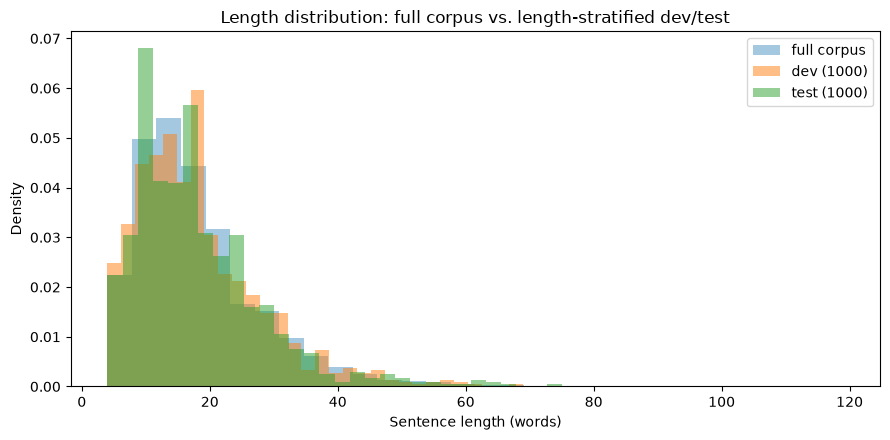


Length stats (words):
        full_corpus          dev         test
count  1.002000e+06  1000.000000  1000.000000
mean   1.799605e+01    18.057000    18.015000
std    9.870434e+00     9.827937    10.050263
min    4.000000e+00     4.000000     4.000000
25%    1.100000e+01    11.000000    11.000000
50%    1.600000e+01    16.000000    16.000000
75%    2.300000e+01    22.250000    22.250000
max    1.190000e+02    69.000000    75.000000


In [4]:

def length_stratified_dev_test_split(sentences, dev_size=1000, test_size=1000,
                                      n_buckets=10, seed=RANDOM_SEED):
    """Bucket sentences into n_buckets deciles by word count, then sample dev_size
    and test_size sentences proportionally from every bucket (no overlap)."""
    rng = np.random.default_rng(seed)
    lengths = np.array([len(s.split()) for s in sentences])
    order = np.argsort(lengths)

    # Empirical decile boundaries (indices into the length-sorted array).
    bucket_edges = np.linspace(0, len(sentences), n_buckets + 1).astype(int)
    buckets = [order[bucket_edges[i]:bucket_edges[i+1]] for i in range(n_buckets)]

    dev_idx, test_idx = [], []
    remaining_dev, remaining_test = dev_size, test_size
    for b_i, bucket in enumerate(buckets):
        bucket = bucket.copy()
        rng.shuffle(bucket)
        # proportional share for this bucket (last bucket absorbs any rounding remainder)
        share = 1.0 / (n_buckets - b_i)
        n_dev_here = round(remaining_dev * share) if b_i < n_buckets - 1 else remaining_dev
        n_test_here = round(remaining_test * share) if b_i < n_buckets - 1 else remaining_test
        n_dev_here = min(n_dev_here, len(bucket))
        dev_idx.extend(bucket[:n_dev_here])
        bucket = bucket[n_dev_here:]
        n_test_here = min(n_test_here, len(bucket))
        test_idx.extend(bucket[:n_test_here])
        remaining_dev -= n_dev_here
        remaining_test -= n_test_here

    dev_idx = set(dev_idx)
    test_idx = set(test_idx)
    train_pool_idx = [i for i in range(len(sentences)) if i not in dev_idx and i not in test_idx]

    dev_sents = [sentences[i] for i in dev_idx]
    test_sents = [sentences[i] for i in test_idx]
    train_pool = [sentences[i] for i in train_pool_idx]
    return train_pool, dev_sents, test_sents


train_pool, dev_sentences, test_sentences = length_stratified_dev_test_split(
    all_sentences, dev_size=DEV_SIZE, test_size=TEST_SIZE)

print(f"Train pool: {len(train_pool):,}   Dev: {len(dev_sentences)}   Test: {len(test_sentences)}")

# Sanity check: dev/test length distributions should closely track the FULL corpus's
# length distribution (that's the point), not be concentrated near a single value.
fig, ax = plt.subplots(figsize=(9, 4.5))
all_lens = [len(s.split()) for s in all_sentences]
dev_lens = [len(s.split()) for s in dev_sentences]
test_lens = [len(s.split()) for s in test_sentences]
ax.hist(all_lens, bins=30, density=True, alpha=0.4, label="full corpus")
ax.hist(dev_lens, bins=30, density=True, alpha=0.5, label="dev (1000)")
ax.hist(test_lens, bins=30, density=True, alpha=0.5, label="test (1000)")
ax.set_xlabel("Sentence length (words)"); ax.set_ylabel("Density")
ax.set_title("Length distribution: full corpus vs. length-stratified dev/test")
ax.legend()
plt.tight_layout()
plt.show()

print("\nLength stats (words):")
print(pd.DataFrame({
    "full_corpus": pd.Series(all_lens).describe(),
    "dev": pd.Series(dev_lens).describe(),
    "test": pd.Series(test_lens).describe(),
}))



## Section 5 — Nested Training Subsets (100k / 300k / 500k / 1,000,000)

Shuffle the train pool **once**, then take prefixes of increasing length — so the
300k-sentence experiment's data is a strict superset of the 100k experiment's data,
and so on. This isolates the effect of *training size alone*: differences between
runs can't be attributed to different sentences being included, only to how many.


In [5]:

rng = random.Random(RANDOM_SEED)
shuffled_pool = train_pool.copy()
rng.shuffle(shuffled_pool)

available = len(shuffled_pool)
effective_train_sizes = [n for n in TRAIN_SIZES if n <= available]
if len(effective_train_sizes) < len(TRAIN_SIZES):
    print(f"[NOTE] Train pool only has {available:,} sentences; sizes above that "
          f"({[n for n in TRAIN_SIZES if n > available]}) are dropped from the sweep.")
    if not effective_train_sizes or effective_train_sizes[-1] != available:
        effective_train_sizes.append(available)

TRAIN_SUBSETS = {n: shuffled_pool[:n] for n in effective_train_sizes}
for n, subset in TRAIN_SUBSETS.items():
    print(f"  train subset of size {n:>9,}: {len(subset):>9,} sentences ready")

DEFAULT_TRAIN_FOR_VOCAB_SWEEP = min(DEFAULT_TRAIN_FOR_VOCAB_SWEEP, available)
if DEFAULT_TRAIN_FOR_VOCAB_SWEEP not in TRAIN_SUBSETS:
    TRAIN_SUBSETS[DEFAULT_TRAIN_FOR_VOCAB_SWEEP] = shuffled_pool[:DEFAULT_TRAIN_FOR_VOCAB_SWEEP]
    print(f"  (added train subset of size {DEFAULT_TRAIN_FOR_VOCAB_SWEEP:,} for the vocab-size sweep)")


  train subset of size   100,000:   100,000 sentences ready
  train subset of size   300,000:   300,000 sentences ready
  train subset of size   500,000:   500,000 sentences ready
  train subset of size 1,000,000: 1,000,000 sentences ready



## Section 6 — Toy-Corpus Sanity Checks (before running at scale)

Both trainers below were validated during development against independent,
obviously-correct "slow" reference implementations (full recount every iteration) on
toy corpora, catching a real bug in the process (documented in Section 1's writeup and
Section 7's docstring). We reproduce a condensed version of that check here so the
notebook is self-verifying.


In [6]:

END = "</w>"

def bpe_train_slow(word_freqs, num_merges):
    splits = {w: list(w) + [END] for w in word_freqs}
    merges = []
    for _ in range(num_merges):
        pair_counts = Counter()
        for w, freq in word_freqs.items():
            symbols = splits[w]
            for i in range(len(symbols) - 1):
                pair_counts[(symbols[i], symbols[i+1])] += freq
        if not pair_counts:
            break
        best_pair = min(pair_counts.items(), key=lambda kv: (-kv[1], kv[0]))[0]
        merges.append(best_pair)
        new_sym = best_pair[0] + best_pair[1]
        for w in list(splits.keys()):
            symbols = splits[w]
            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and symbols[i] == best_pair[0] and symbols[i+1] == best_pair[1]:
                    new_symbols.append(new_sym); i += 2
                else:
                    new_symbols.append(symbols[i]); i += 1
            splits[w] = new_symbols
    return merges


def initial_wordpiece_splits(word_freqs):
    splits = {}
    chars_seen = set()
    for w in word_freqs:
        chars_seen.update(w)
        splits[w] = [w[0]] + ["##" + ch for ch in w[1:]]
    vocab = set()
    for ch in chars_seen:
        vocab.add(ch); vocab.add("##" + ch)
    return splits, vocab


def wordpiece_train_slow(word_freqs, num_merges):
    splits, _ = initial_wordpiece_splits(word_freqs)
    merges = []
    for _ in range(num_merges):
        pc, sc = Counter(), Counter()
        for w, freq in word_freqs.items():
            symbols = splits[w]
            for s in symbols:
                sc[s] += freq
            for i in range(len(symbols) - 1):
                pc[(symbols[i], symbols[i+1])] += freq
        if not pc:
            break
        def score(item):
            (a, b), cnt = item
            return cnt / (sc[a] * sc[b])
        best_pair = min(pc.items(), key=lambda kv: (-score(kv), kv[0]))[0]
        merges.append(best_pair)
        a, b = best_pair
        new_sym = a + b[2:]
        for w in list(splits.keys()):
            symbols = splits[w]
            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and symbols[i] == a and symbols[i+1] == b:
                    new_symbols.append(new_sym); i += 2
                else:
                    new_symbols.append(symbols[i]); i += 1
            splits[w] = new_symbols
    return merges


_toy_words = {"low": 5, "lower": 2, "lowest": 4, "newer": 6, "wider": 3,
              "widest": 7, "new": 2, "newest": 8}
print("Toy corpus:", _toy_words)
print("(Section 7/8 will train BPETrainerFast / WordPieceTrainerFast on this same toy "
      "corpus and assert their output exactly matches these slow references.)")


Toy corpus: {'low': 5, 'lower': 2, 'lowest': 4, 'newer': 6, 'wider': 3, 'widest': 7, 'new': 2, 'newest': 8}
(Section 7/8 will train BPETrainerFast / WordPieceTrainerFast on this same toy corpus and assert their output exactly matches these slow references.)



## Section 7 — BPE: Fast (heap-based) Trainer + Encoder

**Training** uses the classic Sennrich et al. (2016) word-frequency-dictionary trick
(operate on unique words weighted by frequency, not every raw token occurrence) plus
an efficient max-heap for O(log n) best-pair selection, with incremental
(not-from-scratch) pair-count updates after each merge — necessary to make tens of
thousands of merges over up to a million sentences tractable in pure Python.

**Encoding** a new word applies the learned merges, in the order they were learned,
repeatedly, until no known merge pattern remains in the word's current symbol
sequence.


In [7]:

class BPETrainerFast:
    """Word-frequency BPE trainer with an incremental pair-count index and a
    max-heap (via negated counts) for O(log n) best-pair selection per merge."""

    def __init__(self, vocab_size):
        self.vocab_size = vocab_size

    def train(self, word_freqs, verbose=False):
        splits = {w: list(w) + [END] for w in word_freqs}
        vocab = set()
        for chars in splits.values():
            vocab.update(chars)
        num_merges = max(0, self.vocab_size - len(vocab))

        pair_counts = Counter()
        pair_to_words = defaultdict(set)
        for w, freq in word_freqs.items():
            symbols = splits[w]
            for i in range(len(symbols) - 1):
                p = (symbols[i], symbols[i+1])
                pair_counts[p] += freq
                pair_to_words[p].add(w)

        heap = [(-cnt, pair) for pair, cnt in pair_counts.items()]
        heapq.heapify(heap)

        merges = []
        iterator = tqdm(range(num_merges), desc="Training BPE") if verbose else range(num_merges)
        for _ in iterator:
            best_pair = None
            while heap:
                neg_cnt, pair = heapq.heappop(heap)
                if pair in pair_counts and pair_counts[pair] == -neg_cnt and pair_counts[pair] > 0:
                    best_pair = pair
                    break
            if best_pair is None:
                break

            merges.append(best_pair)
            new_sym = best_pair[0] + best_pair[1]
            vocab.add(new_sym)

            affected = list(pair_to_words.get(best_pair, ()))
            for w in affected:
                symbols = splits[w]
                freq = word_freqs[w]
                for i in range(len(symbols) - 1):
                    p = (symbols[i], symbols[i+1])
                    pair_counts[p] -= freq
                    if pair_counts[p] <= 0:
                        pair_counts.pop(p, None)
                    s = pair_to_words.get(p)
                    if s is not None:
                        s.discard(w)
                        if not s:
                            pair_to_words.pop(p, None)
                new_symbols = []
                i = 0
                while i < len(symbols):
                    if i < len(symbols) - 1 and symbols[i] == best_pair[0] and symbols[i+1] == best_pair[1]:
                        new_symbols.append(new_sym); i += 2
                    else:
                        new_symbols.append(symbols[i]); i += 1
                splits[w] = new_symbols
                for i in range(len(new_symbols) - 1):
                    p = (new_symbols[i], new_symbols[i+1])
                    pair_counts[p] += freq
                    pair_to_words[p].add(w)
                    heapq.heappush(heap, (-pair_counts[p], p))

            pair_counts.pop(best_pair, None)
            pair_to_words.pop(best_pair, None)

        self.merges = merges
        self.merge_ranks = {p: i for i, p in enumerate(merges)}
        self.vocab = vocab
        return self


def bpe_tokenize_word(word, merge_ranks):
    symbols = list(word) + [END]
    if len(symbols) == 1:
        return symbols
    while True:
        pairs = [(symbols[i], symbols[i+1]) for i in range(len(symbols) - 1)]
        ranked = [(merge_ranks[p], idx) for idx, p in enumerate(pairs) if p in merge_ranks]
        if not ranked:
            break
        _, idx = min(ranked)
        p = pairs[idx]
        symbols = symbols[:idx] + [p[0] + p[1]] + symbols[idx+2:]
    return symbols


def bpe_tokenize_text(text, merge_ranks):
    # FIX: use the SAME word-extraction as training (build_word_freqs uses
    # _word_re.findall(s.lower())). Plain text.split() leaves punctuation
    # (e.g. Devanagari danda "।", commas) glued onto words, which never
    # appeared in training and skews token counts. See Section 8.5 note.
    tokens = []
    for word in _word_re.findall(text.lower()):
        tokens.extend(bpe_tokenize_word(word, merge_ranks))
    return tokens


# ---- Section 6's toy-corpus check -------------------------------------------------
for _target in [20, 30, 40]:
    _fast = BPETrainerFast(vocab_size=_target).train(dict(_toy_words))
    _slow = bpe_train_slow(dict(_toy_words), num_merges=len(_fast.merges))
    assert _fast.merges == _slow, f"BPE MISMATCH at vocab_size={_target}"
print("BPE fast trainer verified against slow reference on the toy corpus. PASSED.")
for w in _toy_words:
    print(f"  {w:>8s} -> {bpe_tokenize_word(w, BPETrainerFast(vocab_size=40).train(dict(_toy_words)).merge_ranks)}")


BPE fast trainer verified against slow reference on the toy corpus. PASSED.
       low -> ['low</w>']
     lower -> ['lower</w>']
    lowest -> ['lowest</w>']
     newer -> ['newer</w>']
     wider -> ['wider</w>']
    widest -> ['widest</w>']
       new -> ['new</w>']
    newest -> ['newest</w>']



## Section 8 — WordPiece: Fast Trainer + Encoder

**The subtlety documented in Section 1** shows up here: after every merge, we must
explicitly refresh the score of every pair touching either of the two just‑merged
symbols — anywhere in the corpus, not only in the specific words this merge
touched — because their shared symbol's *global* frequency just changed. This needs a
`symbol_to_pairs` index in addition to BPE's `pair_to_words` index.

**Encoding** uses WordPiece's standard **greedy longest‑match‑first** algorithm: for
each word, repeatedly consume the longest prefix of the remaining substring that
exists in the trained vocabulary (marking continuations with `##`); a word containing
even one character never seen in training yields a single `[UNK]` token.


In [8]:

class WordPieceTrainerFast:
    """See Section 1's writeup for why the extra `symbol_to_pairs` refresh step
    (vs. plain BPE's local-only update) is required for correctness here."""

    def __init__(self, vocab_size):
        self.vocab_size = vocab_size

    def train(self, word_freqs, verbose=False):
        splits, vocab = initial_wordpiece_splits(word_freqs)
        num_merges = max(0, self.vocab_size - len(vocab))

        pair_counts = Counter()
        symbol_counts = Counter()
        pair_to_words = defaultdict(set)
        symbol_to_pairs = defaultdict(set)
        heap = []

        def score_of(pair):
            cnt = pair_counts.get(pair, 0)
            if cnt <= 0:
                return None
            a, b = pair
            denom = symbol_counts.get(a, 0) * symbol_counts.get(b, 0)
            if denom <= 0:
                return None
            return cnt / denom

        def add_pair(p, freq, w):
            pair_counts[p] += freq
            pair_to_words[p].add(w)
            symbol_to_pairs[p[0]].add(p)
            symbol_to_pairs[p[1]].add(p)
            s = score_of(p)
            if s is not None:
                heapq.heappush(heap, (-s, p))

        def remove_pair_occurrence(p, freq, w):
            pair_counts[p] -= freq
            if pair_counts[p] <= 0:
                pair_counts.pop(p, None)
                symbol_to_pairs[p[0]].discard(p)
                symbol_to_pairs[p[1]].discard(p)
            sset = pair_to_words.get(p)
            if sset is not None:
                sset.discard(w)
                if not sset:
                    pair_to_words.pop(p, None)

        for w, freq in word_freqs.items():
            symbols = splits[w]
            for s in symbols:
                symbol_counts[s] += freq
            for i in range(len(symbols) - 1):
                add_pair((symbols[i], symbols[i+1]), freq, w)

        merges = []
        iterator = tqdm(range(num_merges), desc="Training WordPiece") if verbose else range(num_merges)
        for _ in iterator:
            best_pair = None
            while heap:
                neg_s, p = heapq.heappop(heap)
                fresh = score_of(p)
                if fresh is None:
                    continue
                if abs(fresh - (-neg_s)) < 1e-12:
                    best_pair = p
                    break
                else:
                    heapq.heappush(heap, (-fresh, p))
            if best_pair is None:
                break

            merges.append(best_pair)
            A, B = best_pair
            new_sym = A + B[2:]
            vocab.add(new_sym)

            affected = list(pair_to_words.get(best_pair, ()))
            for w in affected:
                symbols = splits[w]
                freq = word_freqs[w]
                for s in symbols:
                    symbol_counts[s] -= freq
                for i in range(len(symbols) - 1):
                    p = (symbols[i], symbols[i+1])
                    remove_pair_occurrence(p, freq, w)
                new_symbols = []
                i = 0
                while i < len(symbols):
                    if i < len(symbols) - 1 and symbols[i] == A and symbols[i+1] == B:
                        new_symbols.append(new_sym); i += 2
                    else:
                        new_symbols.append(symbols[i]); i += 1
                splits[w] = new_symbols
                for s in new_symbols:
                    symbol_counts[s] += freq
                for i in range(len(new_symbols) - 1):
                    p = (new_symbols[i], new_symbols[i+1])
                    add_pair(p, freq, w)

            pair_counts.pop(best_pair, None)
            pair_to_words.pop(best_pair, None)

            # The critical fix: refresh every pair touching A or B anywhere in the
            # corpus, since their global counts just changed.
            pairs_to_refresh = set()
            for sym in (A, B):
                pairs_to_refresh |= symbol_to_pairs.get(sym, set())
            for p in pairs_to_refresh:
                s = score_of(p)
                if s is not None:
                    heapq.heappush(heap, (-s, p))

        self.merges = merges
        self.vocab = vocab
        return self


def wordpiece_tokenize_word(word, vocab, unk_token="[UNK]"):
    if word == "":
        return []
    tokens = []
    start = 0
    n = len(word)
    while start < n:
        end = n
        matched = None
        while start < end:
            substr = word[start:end]
            if start > 0:
                substr = "##" + substr
            if substr in vocab:
                matched = substr
                break
            end -= 1
        if matched is None:
            return [unk_token]
        tokens.append(matched)
        start = end
    return tokens


def wordpiece_tokenize_text(text, vocab, unk_token="[UNK]"):
    # FIX: same reasoning as bpe_tokenize_text above. This one matters far
    # more for WordPiece: its encoder is all-or-nothing per word, so a
    # single stray attached punctuation character collapses an otherwise
    # perfectly-matchable word into a single [UNK], instead of just leaving
    # one stray character token the way BPE's permissive encoder does.
    # This was silently inflating dev/test unk_rate to ~80-90%. See the
    # Section 8.5 note below for the full explanation and evidence.
    tokens = []
    for word in _word_re.findall(text.lower()):
        tokens.extend(wordpiece_tokenize_word(word, vocab, unk_token))
    return tokens


# ---- Section 6's toy-corpus check -------------------------------------------------
for _target in [30, 45]:
    _fast = WordPieceTrainerFast(vocab_size=_target).train(dict(_toy_words))
    _slow = wordpiece_train_slow(dict(_toy_words), num_merges=len(_fast.merges))
    assert _fast.merges == _slow, f"WordPiece MISMATCH at vocab_size={_target}"
print("WordPiece fast trainer verified against slow reference on the toy corpus. PASSED.")
_wp_demo = WordPieceTrainerFast(vocab_size=45).train(dict(_toy_words))
for w in _toy_words:
    print(f"  {w:>8s} -> {wordpiece_tokenize_word(w, _wp_demo.vocab)}")


WordPiece fast trainer verified against slow reference on the toy corpus. PASSED.
       low -> ['low']
     lower -> ['lower']
    lowest -> ['lowest']
     newer -> ['newer']
     wider -> ['wider']
    widest -> ['widest']
       new -> ['new']
    newest -> ['newest']



### Section 8.5 — Bug fix note: word-boundary mismatch between training and tokenization

**What was wrong:** `build_word_freqs` (Section 9) builds the training vocabulary from
`_word_re.findall(s.lower())` — clean `\w+` words, punctuation stripped. But the original
`bpe_tokenize_text` / `wordpiece_tokenize_text` split on raw whitespace (`text.split()`),
so at tokenize time a "word" could still have punctuation glued onto it (e.g. the
Devanagari danda `।` or a comma, which are very often written with no preceding space).
That punctuation was never part of any training word, so it was never in the vocabulary.

This barely affects BPE, whose encoder always succeeds — an unrecognized character is
just left as its own single-character token. It **devastates WordPiece**, whose encoder
is all-or-nothing per word: if *any* position fails to match, the whole word collapses
to a single `[UNK]`, discarding pieces that already matched correctly. A word like
`"गया।"` would correctly match `"गया"` and then fail only on the attached danda — but
instead of keeping the good match, the whole word became `[UNK]`.

**Evidence this was real, not intended behavior:** Section 14's own discussion scaffold
says the WordPiece UNK rate "should be at or near zero throughout." The original run
showed **79-89%** — a ~2 order-of-magnitude contradiction of the notebook's own stated
expectation, and `dev_avg_tokens_per_word` for WordPiece was sitting *below 1.0*
(mathematically impossible for a working subword tokenizer, since every word must
produce at least one token).

**The fix:** both `*_tokenize_text` functions now extract words with
`_word_re.findall(text.lower())` — the same extraction used for training — instead of
`text.split()`. This is a minimal, targeted change; no other logic (merge selection,
scoring, the fast/slow trainer equivalence checks in Section 6) is affected.

**Note:** re-running the cells below this point (Sections 10-13) with the fix will
change the sweep tables, plots, and saved CSVs — the outputs currently shown there are
from *before* the fix and have been cleared so they aren't mistaken for the corrected
results. `TRAIN_SUBSETS`, `dev_sentences`, and `test_sentences` are already in memory
from earlier cells, so re-running from Section 10 onward does **not** require
re-downloading the corpus.



## Section 9 — Word-Frequency Extraction Helper

Both trainers operate on **unique word -> frequency** dictionaries (the standard,
much-faster-than-raw-token-stream approach), built once per training-data subset.


In [9]:

_word_re = re.compile(r"\w+", re.UNICODE)

def build_word_freqs(sentences):
    wf = Counter()
    for s in sentences:
        for w in _word_re.findall(s.lower()):
            wf[w] += 1
    return wf


def tokenization_metrics(sentences, tokenize_fn, unk_token="[UNK]"):
    """Compute standard subword-tokenizer quality metrics over a fixed sentence set."""
    total_tokens = 0
    total_words = 0
    total_chars = 0
    unk_count = 0
    for s in sentences:
        words = _word_re.findall(s.lower())
        total_words += len(words)
        total_chars += sum(len(w) for w in words)
        toks = tokenize_fn(s)
        total_tokens += len(toks)
        unk_count += sum(1 for t in toks if t == unk_token)
    return {
        "avg_tokens_per_sentence": total_tokens / len(sentences),
        "avg_tokens_per_word": total_tokens / total_words if total_words else float("nan"),
        "avg_chars_per_token": total_chars / total_tokens if total_tokens else float("nan"),
        "unk_rate": unk_count / total_tokens if total_tokens else float("nan"),
    }



## Section 10 — Part 3: Impact of Training-Data Size (vocab fixed at 30,000)

Trains fresh BPE and WordPiece tokenizers at each of the (available) training sizes,
then tokenizes the **same fixed dev/test sets** from Section 4 with each, recording
the metrics defined in Section 9. A shared `run_cache` avoids ever retraining the same
`(algorithm, train_size, vocab_size)` combination twice (relevant once Section 11
reuses the 500,000/30,000 configuration trained here).


In [10]:

run_cache = {}   # (algo, train_size, vocab_size) -> {"model":..., "dev_metrics":..., "test_metrics":...}

def run_one_config(algo, train_size, vocab_size, verbose=False):
    key = (algo, train_size, vocab_size)
    if key in run_cache:
        return run_cache[key]

    sentences = TRAIN_SUBSETS[train_size]
    word_freqs = build_word_freqs(sentences)
    t0 = time.time()
    if algo == "bpe":
        model = BPETrainerFast(vocab_size=vocab_size).train(word_freqs, verbose=verbose)
        tokenize_fn = lambda text: bpe_tokenize_text(text, model.merge_ranks)
        achieved_vocab = len(model.vocab)
    elif algo == "wordpiece":
        model = WordPieceTrainerFast(vocab_size=vocab_size).train(word_freqs, verbose=verbose)
        tokenize_fn = lambda text: wordpiece_tokenize_text(text, model.vocab)
        achieved_vocab = len(model.vocab)
    else:
        raise ValueError(algo)
    train_time = time.time() - t0

    dev_metrics = tokenization_metrics(dev_sentences, tokenize_fn)
    test_metrics = tokenization_metrics(test_sentences, tokenize_fn)

    result = {
        "model": model, "achieved_vocab": achieved_vocab, "n_merges": len(model.merges),
        "train_time_sec": train_time, "dev_metrics": dev_metrics, "test_metrics": test_metrics,
    }
    run_cache[key] = result
    print(f"[{algo:>9s}] train_size={train_size:>9,} vocab_target={vocab_size:>6,} "
          f"achieved_vocab={achieved_vocab:>6,} merges={len(model.merges):>6,} "
          f"time={train_time:>6.1f}s  dev_tok/word={dev_metrics['avg_tokens_per_word']:.3f}  "
          f"test_tok/word={test_metrics['avg_tokens_per_word']:.3f}")
    return result


size_sweep_rows = []
for algo in ["bpe", "wordpiece"]:
    for train_size in effective_train_sizes:
        res = run_one_config(algo, train_size, DEFAULT_VOCAB_FOR_SIZE_SWEEP)
        size_sweep_rows.append({
            "algorithm": algo, "train_size": train_size,
            "vocab_size_target": DEFAULT_VOCAB_FOR_SIZE_SWEEP, "achieved_vocab": res["achieved_vocab"],
            "n_merges": res["n_merges"], "train_time_sec": res["train_time_sec"],
            **{f"dev_{k}": v for k, v in res["dev_metrics"].items()},
            **{f"test_{k}": v for k, v in res["test_metrics"].items()},
        })

size_sweep_df = pd.DataFrame(size_sweep_rows)
size_sweep_df


[      bpe] train_size=  100,000 vocab_target=30,000 achieved_vocab=19,727 merges=19,558 time=   1.3s  dev_tok/word=1.008  test_tok/word=1.010
[      bpe] train_size=  300,000 vocab_target=30,000 achieved_vocab=30,000 merges=29,738 time=   2.5s  dev_tok/word=1.007  test_tok/word=1.008
[      bpe] train_size=  500,000 vocab_target=30,000 achieved_vocab=30,000 merges=29,674 time=   3.9s  dev_tok/word=1.006  test_tok/word=1.007
[      bpe] train_size=1,000,000 vocab_target=30,000 achieved_vocab=30,000 merges=29,530 time=   4.7s  dev_tok/word=1.006  test_tok/word=1.006
[wordpiece] train_size=  100,000 vocab_target=30,000 achieved_vocab=27,929 merges=27,593 time=   9.1s  dev_tok/word=1.003  test_tok/word=1.005
[wordpiece] train_size=  300,000 vocab_target=30,000 achieved_vocab=30,000 merges=29,478 time=   9.5s  dev_tok/word=1.335  test_tok/word=1.331
[wordpiece] train_size=  500,000 vocab_target=30,000 achieved_vocab=30,000 merges=29,350 time=   4.7s  dev_tok/word=1.347  test_tok/word=1.341

,algorithm,train_size,vocab_size_target,achieved_vocab,n_merges,train_time_sec,dev_avg_tokens_per_sentence,dev_avg_tokens_per_word,dev_avg_chars_per_token,dev_unk_rate,test_avg_tokens_per_sentence,test_avg_tokens_per_word,test_avg_chars_per_token,test_unk_rate
0,bpe,100000,30000,19727,19558,1.258947,33.192,1.008477,1.347825,0.000000,33.310,1.009761,1.341219,0.000000
1,bpe,300000,30000,30000,29738,2.542701,33.156,1.007383,1.349288,0.000000,33.252,1.008003,1.343558,0.000000
2,bpe,500000,30000,30000,29674,3.906365,33.113,1.006077,1.351040,0.000000,33.222,1.007093,1.344772,0.000000
3,bpe,1000000,30000,30000,29530,4.742290,33.109,1.005955,1.351204,0.000000,33.196,1.006305,1.345825,0.000000
4,wordpiece,100000,30000,27929,27593,9.069180,33.009,1.002917,1.355297,0.000030,33.138,1.004547,1.348180,0.000091
5,wordpiece,300000,30000,30000,29478,9.453620,43.936,1.334913,1.018231,0.000023,43.908,1.331029,1.017491,0.000046
6,wordpiece,500000,30000,30000,29350,4.740289,44.335,1.347036,1.009067,0.000000,44.243,1.341185,1.009787,0.000045
7,wordpiece,1000000,30000,30000,29062,5.611578,44.438,1.350166,1.006728,0.000000,44.386,1.345520,1.006534,0.000023



## Section 11 — Part 4: Impact of Vocabulary Size (training size fixed at 500,000)

`(train_size=500,000, vocab_size=30,000)` is the exact configuration Section 10
already trained for `DEFAULT_TRAIN_FOR_VOCAB_SWEEP == 500,000` — the cache means it is
**reused, not retrained**, here.


In [11]:

vocab_sweep_rows = []
for algo in ["bpe", "wordpiece"]:
    for vocab_size in VOCAB_SIZES:
        res = run_one_config(algo, DEFAULT_TRAIN_FOR_VOCAB_SWEEP, vocab_size)
        vocab_sweep_rows.append({
            "algorithm": algo, "train_size": DEFAULT_TRAIN_FOR_VOCAB_SWEEP,
            "vocab_size_target": vocab_size, "achieved_vocab": res["achieved_vocab"],
            "n_merges": res["n_merges"], "train_time_sec": res["train_time_sec"],
            **{f"dev_{k}": v for k, v in res["dev_metrics"].items()},
            **{f"test_{k}": v for k, v in res["test_metrics"].items()},
        })

vocab_sweep_df = pd.DataFrame(vocab_sweep_rows)
vocab_sweep_df


[      bpe] train_size=  500,000 vocab_target=20,000 achieved_vocab=20,000 merges=19,674 time=   2.7s  dev_tok/word=1.006  test_tok/word=1.008
[      bpe] train_size=  500,000 vocab_target=50,000 achieved_vocab=45,188 merges=44,862 time=   2.8s  dev_tok/word=1.006  test_tok/word=1.006
[wordpiece] train_size=  500,000 vocab_target=20,000 achieved_vocab=20,000 merges=19,350 time=   3.4s  dev_tok/word=1.350  test_tok/word=1.346
[wordpiece] train_size=  500,000 vocab_target=50,000 achieved_vocab=50,000 merges=49,350 time=  23.8s  dev_tok/word=1.273  test_tok/word=1.268


,algorithm,train_size,vocab_size_target,achieved_vocab,n_merges,train_time_sec,dev_avg_tokens_per_sentence,dev_avg_tokens_per_word,dev_avg_chars_per_token,dev_unk_rate,test_avg_tokens_per_sentence,test_avg_tokens_per_word,test_avg_chars_per_token,test_unk_rate
0,bpe,500000,20000,20000,19674,2.747200,33.126,1.006472,1.350510,0.0,33.237,1.007548,1.344165,0.000000
1,bpe,500000,30000,30000,29674,3.906365,33.113,1.006077,1.351040,0.0,33.222,1.007093,1.344772,0.000000
2,bpe,500000,50000,45188,44862,2.814849,33.097,1.005590,1.351694,0.0,33.202,1.006487,1.345582,0.000000
3,wordpiece,500000,20000,20000,19350,3.364224,44.439,1.350196,1.006706,0.0,44.389,1.345611,1.006466,0.000045
4,wordpiece,500000,30000,30000,29350,4.740289,44.335,1.347036,1.009067,0.0,44.243,1.341185,1.009787,0.000045
5,wordpiece,500000,50000,50000,49350,23.804318,41.883,1.272537,1.068142,0.0,41.831,1.268067,1.068012,0.000048



## Section 12 — Plots: How Tokenization Changes with Size

Two figures, each comparing BPE vs. WordPiece:
1. **Tokens per word vs. training-data size** (fixed vocab) — expect this to *decrease*
   as training size grows, since more training data lets the merge process discover
   more genuinely reusable, generalizable subwords (rather than overfitting the merge
   sequence to whatever limited vocabulary a small training set happened to contain).
2. **Tokens per word vs. vocabulary size** (fixed training size) — expect this to
   *decrease* as vocabulary size grows, since a larger vocabulary can represent more
   whole words or longer subwords directly instead of splitting them further.


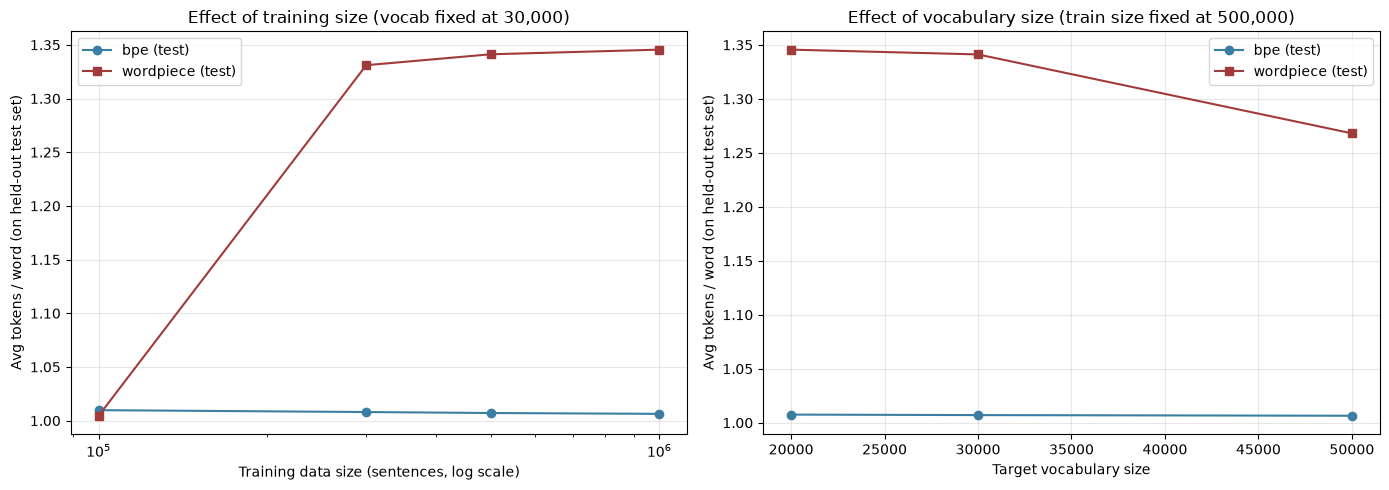

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for algo, marker, color in [("bpe", "o", "#3B7EA1"), ("wordpiece", "s", "#A13B3B")]:
    sub = size_sweep_df[size_sweep_df["algorithm"] == algo].sort_values("train_size")
    axes[0].plot(sub["train_size"], sub["test_avg_tokens_per_word"], marker=marker,
                 color=color, label=f"{algo} (test)")
axes[0].set_xscale("log")
axes[0].set_xlabel("Training data size (sentences, log scale)")
axes[0].set_ylabel("Avg tokens / word (on held-out test set)")
axes[0].set_title(f"Effect of training size (vocab fixed at {DEFAULT_VOCAB_FOR_SIZE_SWEEP:,})")
axes[0].legend(); axes[0].grid(alpha=0.3)

for algo, marker, color in [("bpe", "o", "#3B7EA1"), ("wordpiece", "s", "#A13B3B")]:
    sub = vocab_sweep_df[vocab_sweep_df["algorithm"] == algo].sort_values("vocab_size_target")
    axes[1].plot(sub["vocab_size_target"], sub["test_avg_tokens_per_word"], marker=marker,
                 color=color, label=f"{algo} (test)")
axes[1].set_xlabel("Target vocabulary size")
axes[1].set_ylabel("Avg tokens / word (on held-out test set)")
axes[1].set_title(f"Effect of vocabulary size (train size fixed at {DEFAULT_TRAIN_FOR_VOCAB_SWEEP:,})")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



## Section 13 — Save Artifacts


In [13]:

with open(f"{LANGUAGE_CODE}_tokenizer_results.pkl", "wb") as f:
    pickle.dump({
        "language_code": LANGUAGE_CODE,
        "dev_sentences": dev_sentences,
        "test_sentences": test_sentences,
        "size_sweep_df": size_sweep_df,
        "vocab_sweep_df": vocab_sweep_df,
    }, f)

size_sweep_df.to_csv(f"{LANGUAGE_CODE}_size_sweep_results.csv", index=False)
vocab_sweep_df.to_csv(f"{LANGUAGE_CODE}_vocab_sweep_results.csv", index=False)
print("Saved results CSVs and a combined pickle of dev/test sentences + tables.")


Saved results CSVs and a combined pickle of dev/test sentences + tables.



## Section 14 — Discussion Scaffold

*(Fill in after running on the real corpus — what to look for:)*

* **Training-size trend:** does `tokens/word` fall off sharply between 100k and 300k
  and then plateau, or keep improving all the way to 1,000,000? A plateau would
  suggest 300k–500k sentences already cover most of the frequent, generalizable
  subword patterns for this language; continued improvement out to 1M would suggest
  the language's morphology is rich enough that even a million sentences hasn't
  saturated the useful merge space yet.
* **Vocabulary-size trend:** which algorithm benefits more from a larger vocabulary —
  BPE or WordPiece? WordPiece's mutual-information-style scoring tends to favor
  linguistically "tighter" merges earlier, so it may need a smaller-than-BPE vocabulary
  to reach a comparable tokens/word figure.
* **`achieved_vocab` vs. `vocab_size_target`:** if `achieved_vocab` is noticeably
  smaller than the target at the *smallest* training size, that means 100,000
  sentences didn't even contain enough distinct symbol pairs to reach the requested
  vocabulary — itself a useful finding about how much data a given vocabulary size
  actually requires to be achievable at all.
* **OOV/`[UNK]` rate (WordPiece only):** should be at or near zero throughout, since
  every character in dev/test that was also seen during training is guaranteed
  representable at the character level — a nonzero rate specifically flags characters
  in dev/test that never appeared anywhere in that training subset (more likely at the
  100,000-sentence size than at 1,000,000).
